# Tutorial 6d: A Complete Tolerance Study

Tutorials [6a](Tutorial_6a_Tolerancing_Sensitivity_Analysis.ipynb) and
[6b](Tutorial_6b_Monte_Carlo_Tolerancing_Analysis.ipynb) introduced sensitivity
and Monte Carlo analyses with *perturbations*, which set absolute values of a
parameter. This tutorial runs a complete tolerance study the way it is usually
done in practice, with *tolerances*: signed deviations from the nominal design,
stated the way a drawing or an optical shop states them, e.g. ±0.05 mm.

We will:

1. choose the performance criteria (operands),
2. add tolerances of several types, with their units and distributions,
3. add a focus compensator,
4. run a sensitivity analysis, with an RSS estimate and a tornado chart,
5. run an inverse sensitivity analysis, which finds the limits that keep the
   performance within a budget,
6. fill a tolerance set from a table of shop tolerances and run a seeded Monte
   Carlo analysis, with yield and percentiles,
7. convert the tolerances to and from an ISO 10110 drawing specification.

The [Tolerancing Guide](../tolerancing_guide.rst) explains each step in more
detail.

In [1]:
import warnings

import pandas as pd

from optiland.iso10110 import DrawingSpec
from optiland.paraxial_path import ParaxialDomainWarning
from optiland.samples.objectives import CookeTriplet
from optiland.tolerancing import (
    InverseSensitivity,
    SensitivityAnalysis,
    Tolerancing,
    drawing_values_from_tolerancing,
    tolerance_registry,
)
from optiland.tolerancing.monte_carlo import MonteCarlo

# Tilts and decenters make the paraxial (first-order) quantities approximate,
# which Optiland reports with a warning on every trial. The operands used here
# are computed by real ray tracing, so the warning is not needed.
warnings.simplefilter("ignore", ParaxialDomainWarning)
pd.set_option("display.width", 120)

## 1. The lens and the performance criteria

We tolerance the Cooke triplet from the sample library. Surfaces 1 and 2 form
the first lens, 3 and 4 the second (surface 4 is the stop) and 5 and 6 the
third; the gap after surface 6 is the back focal distance.

In [2]:
lens = CookeTriplet()
lens.info()

╒════╤═════════════════╤═══════════╤═══════════╤═════════════╤════════════╤═════════╤═════════════════╕
│    │ Type            │ Comment   │    Radius │   Thickness │ Material   │   Conic │   Semi-aperture │
╞════╪═════════════════╪═══════════╪═══════════╪═════════════╪════════════╪═════════╪═════════════════╡
│  0 │ Planar          │           │  inf      │   inf       │ Air        │       0 │         9.19008 │
│  1 │ Standard        │           │   22.0136 │     3.25896 │ SK16       │       0 │         9.19008 │
│  2 │ Standard        │           │ -435.76   │     6.00755 │ Air        │       0 │         7.93701 │
│  3 │ Standard        │           │  -22.2133 │     0.99997 │ F2         │       0 │         4.12082 │
│  4 │ Stop - Standard │           │   20.2919 │     4.75041 │ Air        │       0 │         3.80085 │
│  5 │ Standard        │           │   79.6836 │     2.95208 │ SK16       │       0 │         6.43676 │
│  6 │ Standard        │           │  -18.3953 │    42.2078  │ A

The operands are the performance criteria. They use the same names and inputs
as optimization operands. We follow two of them:

- `rms_spot_size`: the RMS spot radius on axis, in mm;
- `rms_wavefront`: the RMS wavefront error at the edge of the field, in waves.
  This operand is new with the tolerancing rework, together with `mtf` (MTF at
  one frequency) and `boresight_x` / `boresight_y` (the image shift of a field
  point, in milliradians).

Both get `target=0`: the compensator added below minimizes them. Small pupil
samplings keep this tutorial fast; use larger ones for a real study.

We wrap the operands in a function, because the Monte Carlo study in section 5
uses a second tolerancing problem with the same criteria.

In [3]:
def add_operands(tolerancing):
    wavelength = lens.primary_wavelength
    tolerancing.add_operand(
        "rms_spot_size",
        {
            "optic": lens,
            "surface_number": -1,
            "Hx": 0.0,
            "Hy": 0.0,
            "wavelength": wavelength,
            "num_rays": 5,
        },
        target=0.0,
    )
    tolerancing.add_operand(
        "rms_wavefront",
        {
            "optic": lens,
            "Hx": 0.0,
            "Hy": 1.0,
            "num_rays": 6,
            "wavelength": wavelength,
        },
        target=0.0,
    )


tolerancing = Tolerancing(lens)
add_operands(tolerancing)
tolerancing.evaluate()

[0.004338400902229848, 0.42026401744165304]

## 2. Tolerances

`add_tolerance(type, limit)` adds a symmetric tolerance `[-limit, +limit]`
around the nominal value; `minus=` and `plus=` give an asymmetric one. The
registered types are:

In [4]:
tolerance_registry.names()

['abbe',
 'conic',
 'element_decenter',
 'element_roll',
 'element_tilt',
 'fringes',
 'index',
 'irregularity',
 'radius',
 'surface_decenter',
 'surface_tilt',
 'thickness']

Each type has its own units: lens units (mm here) for radius, thickness and
decenters, degrees for tilts and rolls, fringes for power and irregularity,
and absolute index or Abbe-number change for materials. Surface types take
`surface_number`; element types move the surfaces `first` to `last` as one
rigid body, and tilts and rolls turn about a `pivot` (`"center"`, `"first"`,
`"last"` or a distance from the first vertex).

We add six tolerances. The sensitivity analysis, below, plots up to six
perturbations at a time.

In [5]:
tolerancing.add_tolerance("radius", 0.1, surface_number=1)
tolerancing.add_tolerance("fringes", 2, surface_number=2)
tolerancing.add_tolerance("thickness", 0.05, surface_number=3)
tolerancing.add_tolerance("element_decenter", 0.02, first=3, last=4, axis="y")
tolerancing.add_tolerance(
    "element_tilt", 0.03, first=1, last=2, axis="x", pivot="first"
)
tolerancing.add_tolerance("index", 0.001, surface_number=3)

for tolerance in tolerancing.perturbations:
    print(tolerance)

Radius S1: [-0.1, +0.1] lens units
Fringes S2: [-2, +2] fringes
Thickness S3: [-0.05, +0.05] lens units
Element Decenter Y S3-4: [-0.02, +0.02] lens units
Element Tilt X S1-2: [-0.03, +0.03] degrees
Index S3: [-0.001, +0.001] Δn_d


In a trial, deviations are applied in phases, not in the order they were
added: structure (radius, fringes, conic, thickness) first, then material,
then form (irregularity), then rigid-body moves (decenters, tilts, rolls). A
thickness change moves every later surface, so rigid-body moves come last and
are not overwritten.

In [6]:
[t.label for t in tolerancing.ordered_perturbations()]

['Radius S1',
 'Fringes S2',
 'Thickness S3',
 'Index S3',
 'Element Decenter Y S3-4',
 'Element Tilt X S1-2']

Monte Carlo analyses draw each deviation from the tolerance's distribution.
The default, `"normal"`, is a normal distribution truncated at the limits, with
the limits at ±2σ. `"uniform"`, `"parabolic"` (most values near the limits)
and `"end_point"` (only the limits) are also available, through the
`distribution=` argument of `add_tolerance`.

## 3. A focus compensator

After assembly, the image distance is adjusted to the best focus. We model this
with an optimizer compensator on the thickness after surface 6: on every trial,
the compensator minimizes the operands by changing that thickness.

`add_compensator("quick_focus")` is a cheaper alternative that moves the image
surface with the closed-form `QuickFocusSolve` instead of running an
optimizer. It is meant for coaxial systems; see the
[Tolerancing Guide](../tolerancing_guide.rst) for when to use it.

In [7]:
tolerancing.add_compensator("thickness", surface_number=6)

## 4. Sensitivity analysis

A sensitivity analysis applies each tolerance alone, at its lower and at its
upper limit, applies the compensator and evaluates the operands. Each row of
the results is one trial; the last column is the compensator value.

In [8]:
sensitivity = SensitivityAnalysis(tolerancing)
sensitivity.run()
sensitivity.get_results()

,perturbation_type,perturbation_value,0: rms spot size,1: rms wavefront,"C0: Thickness, Surface 6"
0,Radius S1,-0.100,0.014301,0.193638,41.702540
1,Radius S1,0.100,0.012780,0.156504,42.383764
2,Fringes S2,-2.000,0.012985,0.177200,42.079077
3,Fringes S2,2.000,0.014070,0.161726,42.007199
4,Thickness S3,-0.050,0.016607,0.145705,42.005583
5,Thickness S3,0.050,0.010506,0.224766,42.080936
6,Element Decenter Y S3-4,-0.020,0.014372,0.154722,42.033953
7,Element Decenter Y S3-4,0.020,0.013000,0.271902,42.052850
8,Element Tilt X S1-2,-0.030,0.011743,0.196430,42.067585
9,Element Tilt X S1-2,0.030,0.015336,0.161465,42.018659


`rss_estimate()` combines the worst change of each tolerance by root sum of
squares (RSS), a quick estimate of the performance when all tolerances act at
once. `nominal` is the compensated nominal value.

In [9]:
sensitivity.rss_estimate()

,nominal,rss_change,estimate
0: rms spot size,0.013527,0.003805,0.017332
1: rms wavefront,0.168908,0.123148,0.292057


The tornado chart sorts the tolerances by their effect on one operand, the
largest on top. The wavefront error at the edge of the field is most sensitive
to the decenter of the second lens and to the thickness after surface 3.

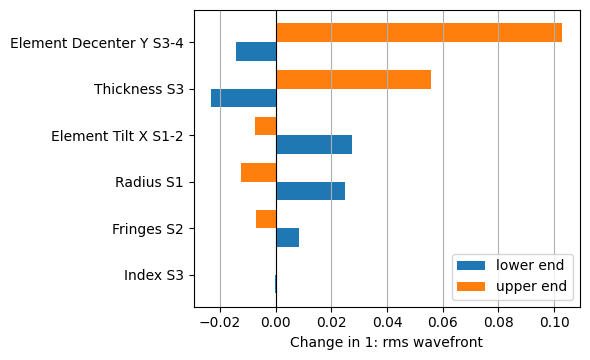

In [10]:
fig, ax = sensitivity.view_tornado(operand_index=1)

## 5. Inverse sensitivity

Inverse sensitivity answers the reverse question: how large may each tolerance
be before an operand changes by more than an allowed amount? Here we allow the
wavefront error to grow by 0.05 waves over the compensated nominal. Each side
of each tolerance is searched on its own.

In [11]:
inverse = InverseSensitivity(tolerancing, max_change={1: 0.05})
inverse.run()
results = inverse.get_results()
results["ratio_minus"] = results["inverse_minus"] / results["minus"]
results["ratio_plus"] = results["inverse_plus"] / results["plus"]
columns = ["tolerance", "plus", "inverse_minus", "inverse_plus"]
results[columns + ["ratio_minus", "ratio_plus"]]

,tolerance,plus,inverse_minus,inverse_plus,ratio_minus,ratio_plus
0,Radius S1,0.100,-0.178277,0.437885,1.782769,4.378852
1,Fringes S2,2.000,-10.063359,30.425188,5.031680,15.212594
2,Thickness S3,0.050,-0.146062,0.045474,2.921244,0.909479
3,Element Decenter Y S3-4,0.020,-0.035301,0.010779,1.765059,0.538953
4,Element Tilt X S1-2,0.030,-0.047469,0.096491,1.582291,3.216378
5,Index S3,0.001,-0.036767,0.034013,36.766741,34.013115


The ratios compare the inverse limits with the current ones, which makes
tolerances in different units comparable. A ratio above 1 means the tolerance
could be loosened on that side; below 1, it alone uses more than the budget.
Here the +y decenter of the second lens and the +0.05 mm thickness after
surface 3 exceed it, while the power of surface 2 could be relaxed a lot.
`inverse.view()` plots the limits, and `inverse.apply_limits()` writes the
inverse limits into the tolerances. We keep the current limits here.

## 6. Monte Carlo from a table of shop tolerances

Writing every tolerance by hand is tedious. `add_default_tolerances` applies a
table to every matching part of the design: surface types to every refracting
surface, `thickness` to every gap except the one before the image (usually
the focus compensator), element types to every lens and material types to
every glass. Decenters and tilts are added about x and about y.

Optiland ships no grade tables: published "commercial" or "precision" values
differ from vendor to vendor, and ISO 10110 defines the notation, not the
values. Pass the values your shop quotes. A table entry is a number (a
symmetric limit) or a dictionary of `add_tolerance` arguments.

In [12]:
shop_table = {
    "radius": 0.1,
    "fringes": 2,
    "thickness": 0.05,
    "surface_tilt": 0.02,
    "element_decenter": 0.02,
    "index": {"limit": 0.001, "distribution": "uniform"},
}

monte_carlo_problem = Tolerancing(lens)
add_operands(monte_carlo_problem)
added = monte_carlo_problem.add_default_tolerances(shop_table)
monte_carlo_problem.add_compensator("thickness", surface_number=6)
print(f"{len(added)} tolerances, for example:")
for tolerance in added[:4]:
    print(" ", tolerance)

38 tolerances, for example:
  Radius S1: [-0.1, +0.1] lens units
  Radius S2: [-0.1, +0.1] lens units
  Radius S3: [-0.1, +0.1] lens units
  Radius S4: [-0.1, +0.1] lens units


A Monte Carlo analysis applies all tolerances at once, each drawn from its
distribution, then compensates and evaluates. With `seed=` the run is
reproducible: each trial draws from its own generator, spawned from the seed.

In [13]:
monte_carlo = MonteCarlo(monte_carlo_problem)
monte_carlo.run(100, seed=42)

`percentiles()` gives the operand and compensator values that 50 %, 90 % and
98 % of the trials do not exceed. `yield_fraction()` gives the fraction of
trials that meet a specification; a key is an operand index or a column name
of `get_results()`.

In [14]:
monte_carlo.percentiles()

,0: rms spot size,1: rms wavefront,"C0: Thickness, Surface 6"
percentile,,,
50.0,0.013444,0.203891,42.050028
90.0,0.016931,0.285741,42.246852
98.0,0.018043,0.379271,42.333115


In [15]:
monte_carlo.yield_fraction({0: ("<=", 0.02), 1: ("<=", 0.25)})

0.81

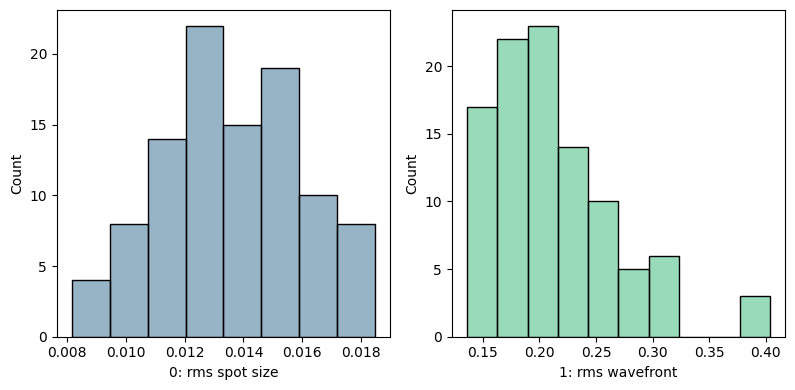

In [16]:
fig, axes = monte_carlo.view_histogram(kde=False)

For a larger run, `run(n, seed=..., workers=4)` splits the trials across four
processes and returns the same results as a serial run with the same seed. It
needs the NumPy backend and tolerances only (no `add_perturbation`
perturbations). On Windows and macOS, call it from a script under
`if __name__ == "__main__":`. This tutorial stays in one process.

## 7. The ISO 10110 bridge

The tolerances of a design end up on its fabrication drawings.
`drawing_values_from_tolerancing` reports the ISO 10110 fields implied by the
tolerances: radius tolerances, `3/` power in fringes and `4/` centering in arc
minutes per surface, and centre-thickness tolerances per element. Some
tolerances have no field on a lens drawing and are not reported: the index
tolerances (ISO 10110 has no index offset), the air-space thicknesses and the
element decenters, which belong to the assembly.

In [17]:
values = drawing_values_from_tolerancing(monte_carlo_problem)
values

{'surfaces': {1: {'r_tolerance': 0.1,
   'test_wavelength': 632.8000000000001,
   'sag_tolerance': 2.0,
   'centration': 1.2},
  2: {'r_tolerance': 0.1,
   'test_wavelength': 632.8000000000001,
   'sag_tolerance': 2.0,
   'centration': 1.2},
  3: {'r_tolerance': 0.1,
   'test_wavelength': 632.8000000000001,
   'sag_tolerance': 2.0,
   'centration': 1.2},
  4: {'r_tolerance': 0.1,
   'test_wavelength': 632.8000000000001,
   'sag_tolerance': 2.0,
   'centration': 1.2},
  5: {'r_tolerance': 0.1,
   'test_wavelength': 632.8000000000001,
   'sag_tolerance': 2.0,
   'centration': 1.2},
  6: {'r_tolerance': 0.1,
   'test_wavelength': 632.8000000000001,
   'sag_tolerance': 2.0,
   'centration': 1.2}},
 'elements': {0: {'ct_tolerance': 0.05},
  1: {'ct_tolerance': 0.05},
  2: {'ct_tolerance': 0.05}}}

These are keyword arguments of `DrawingSpec.set_surface` and
`DrawingSpec.set_element`, so they fill a drawing specification directly (see
[Tutorial 11a](Tutorial_11a_ISO_10110_Drawings.ipynb) for the drawings
themselves).

In [18]:
spec = DrawingSpec(lens)
for surface, fields in values["surfaces"].items():
    spec.set_surface(surface, **fields)
for element, fields in values["elements"].items():
    spec.set_element(element, **fields)

The reverse direction reads the tolerances from a drawing specification, for
example one loaded with `DrawingSpec.load_yaml`. `centering="per_axis"`
(default) gives each tilt axis the full `4/` angle; `centering="rss"` splits it
so that the combined tilt equals the drawn angle.

In [19]:
from_drawing = Tolerancing(lens)
for tolerance in from_drawing.add_tolerances_from_drawing(spec)[:6]:
    print(tolerance)

Radius S1: [-0.1, +0.1] lens units
Fringes S1: [-2, +2] fringes
Tilt X S1: [-0.02, +0.02] degrees
Tilt Y S1: [-0.02, +0.02] degrees
Radius S2: [-0.1, +0.1] lens units
Fringes S2: [-2, +2] fringes


## Summary

- `add_tolerance` states a deviation from nominal with limits, units and a
  distribution; `add_default_tolerances` applies a table of your own values to
  the whole design.
- Compensators model the adjustments made after assembly: an optimizer
  compensator such as a thickness, or the cheaper `"quick_focus"`.
- `SensitivityAnalysis` (with `rss_estimate` and `view_tornado`) shows which
  tolerances matter; `InverseSensitivity` finds the limits that fit a budget.
- `MonteCarlo` with `seed=` gives reproducible yield and percentiles.
- The ISO 10110 bridge moves the tolerances to and from the drawings.

The [Tolerancing Guide](../tolerancing_guide.rst) is the reference for all of
these.